In [19]:
import numpy as np
import matplotlib.pyplot as plt

from datetime import datetime, timedelta
from dateutil.relativedelta import relativedelta

import cartopy.crs as ccrs
web_mercator = ccrs.Mercator.GOOGLE
import cartopy.feature as cfeature
from cartopy.crs import PlateCarree
import matplotlib.colors
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import json

In [20]:
# Setting up datetime array from 1-1-2000 to 12-1-2020
num_months = 21*12 # 21 years with 12 months in this dataset
start = datetime(2000, 1, 1, 0, 0)
time = np.array([start + relativedelta(months=i) for i in range(num_months)])

In [21]:
def get_first_four_digits(number):
  '''
  Returns the first 4 digits of the HUC12 code
  '''
  num_str = str(number)
  if len(num_str) < 4:
      return number # Return the original number if it has less than 4 digits
  else:
      first_four = num_str[:4] # gets the first 4 digits of the HUC12 => HUC4
      return int(first_four) # turns it back into an int

In [22]:
#DICTIONARY with corresponding HUC4 that we will be using in California

d = {'1805': 'San Fransisco Bay', '1802': 'Sacramento'}
d['1809'] = 'Northern Mojave'
d['1810'] = 'Southern Mojave'
d['1804'] = 'San Joaquin'
d['1803'] = 'Tulare Buena Vista'
d['1806'] = 'Central Coastal'
d['1801'] = 'Northern Coastal'
d['1807'] = 'Southern Coastal'

In [23]:
def find_huc(data):
    '''
    INPUT: put in the dataset of water use with conditions:
        - data ranges from 01/01/2000 to 12/01/2020
        - HUC12 in the first row

    OUTPUT: returns water use data...
        - for every month between 01/01/2000 to 12/01/2020
        - within HUC groups 1801, 1802, 1803, 1804, 1805, 1806, 1807, 1809, 1810

    FUNCTION:
        - gets the HUC4 from HUC12
        - combines the data within each HUC12 into their respective HUC4 for the HUC4s that we're looking for
    '''

    header = data[0] # gets all HUC12 codes in one array
    huc4 = [] # array of huc4 codes

    for n in header: # for every HUC12 code
        four = get_first_four_digits(n) # turn it into an HUC4
        huc4.append(four) # add it to the array

    indices = [] # making empty array of indices
    for key in d:
        if key in [str(x) for x in huc4]:
            indices.extend([i for i, x in enumerate(huc4) if str(x) == key])

    huc_groups = {
    1801: [], 1802: [], 1803: [], 1804: [], 1805: [], 1806: [], 1807: [], 1809: [], 1810: []
    }

    for i in indices: # for each index of a numebr in the HUC4 we're interested in
        huc = huc4[i] # get the HUC4 code
        if huc in huc_groups: # finds the HUC4 group that matches
            if len(huc_groups[huc]) == 0: # if there is no data yet for that group
                huc_groups[huc] = data[1:,i] # sets it equal to the column at that index
            else:
                huc_groups[huc] = huc_groups[huc] + data[1:,i] # does element-wise addition

    return huc_groups

In [24]:
def plot_water(huc_group, water_use_type):
    fig, ax = plt.subplots(1, 1, figsize=(15, 8))
    for key in huc_group: # for each HUC4
        ax.plot(time, huc_group[key], label=d[str(key)])  # Plot irrigation over time
    ax.set_title(f'California {water_use_type} Consumptive Use')
    ax.set_xlabel('Time (measured monthly)')
    ax.set_ylabel('Millions of gallons per day')
    plt.legend() #add a legend to the plot

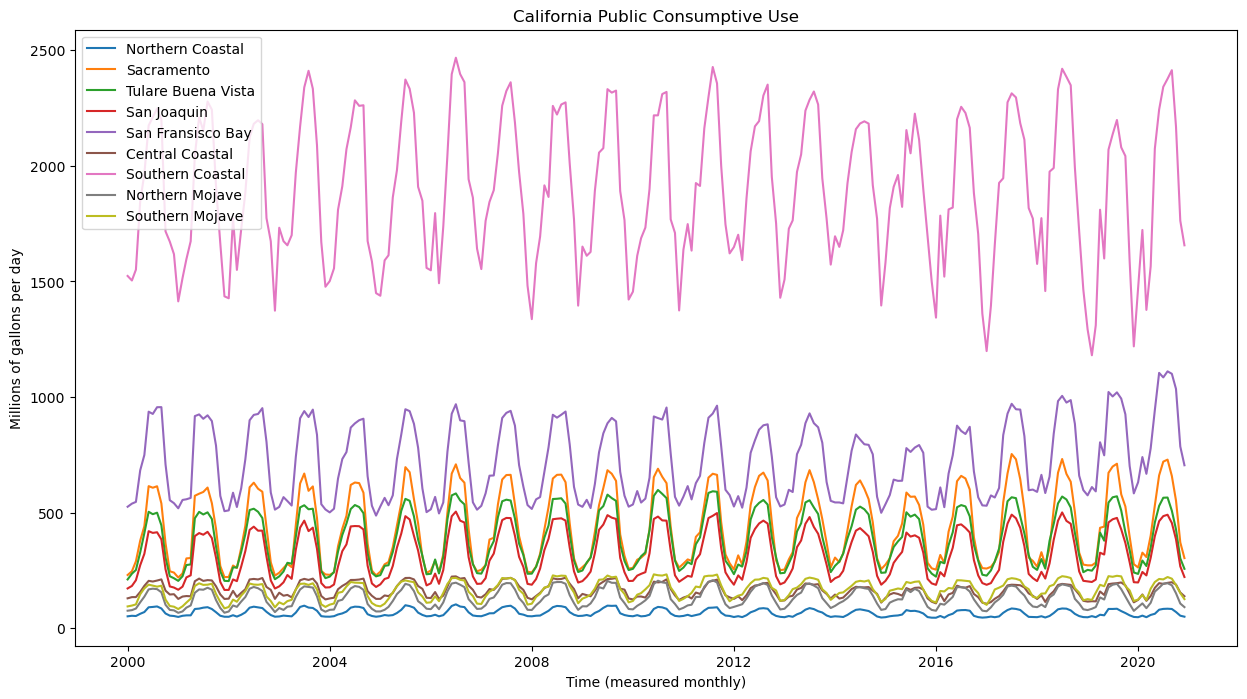

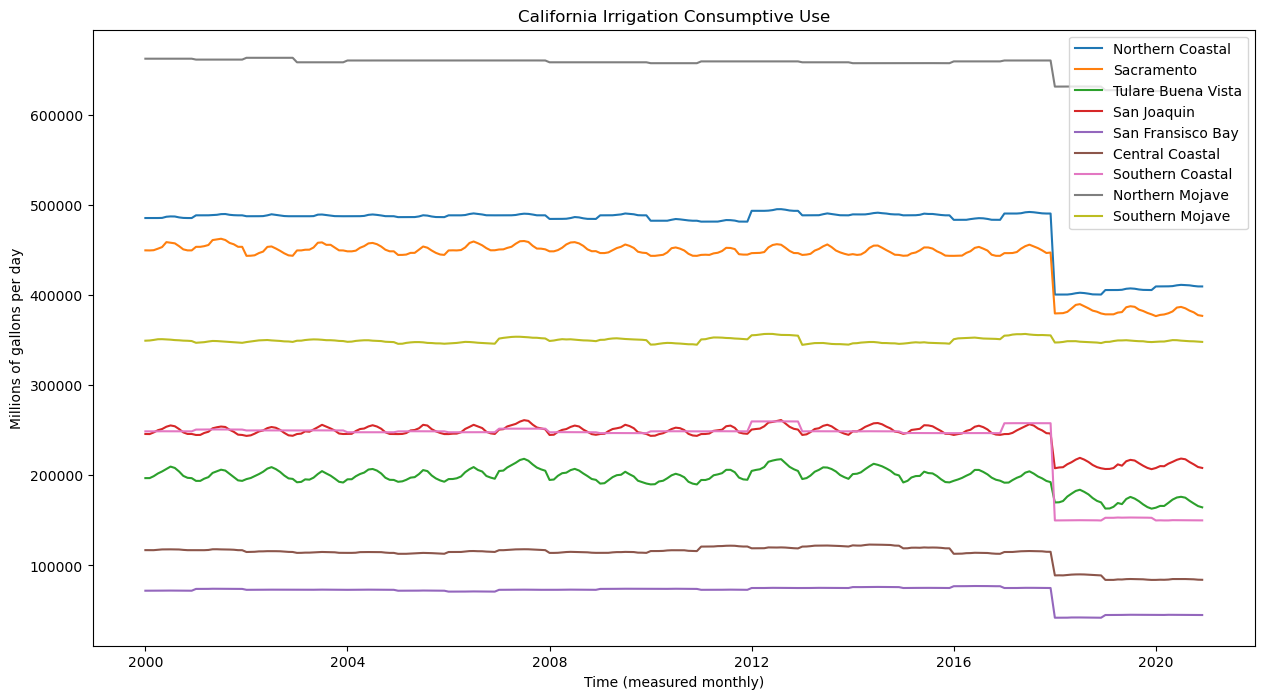

In [25]:
filepath_irr = 'Irr_CU_HUC12_Tot_monthly_2000_2020.csv'
filepath_ps = 'PS_HUC12_Tot_2000_2020.csv'

irr_data = np.genfromtxt(filepath_irr, delimiter=',')
ps_data = np.genfromtxt(filepath_ps, delimiter=',')

huc_PS = find_huc(ps_data)
huc_Irr = find_huc(irr_data)

plot_water(huc_PS, 'Public')
plot_water(huc_Irr, 'Irrigation')

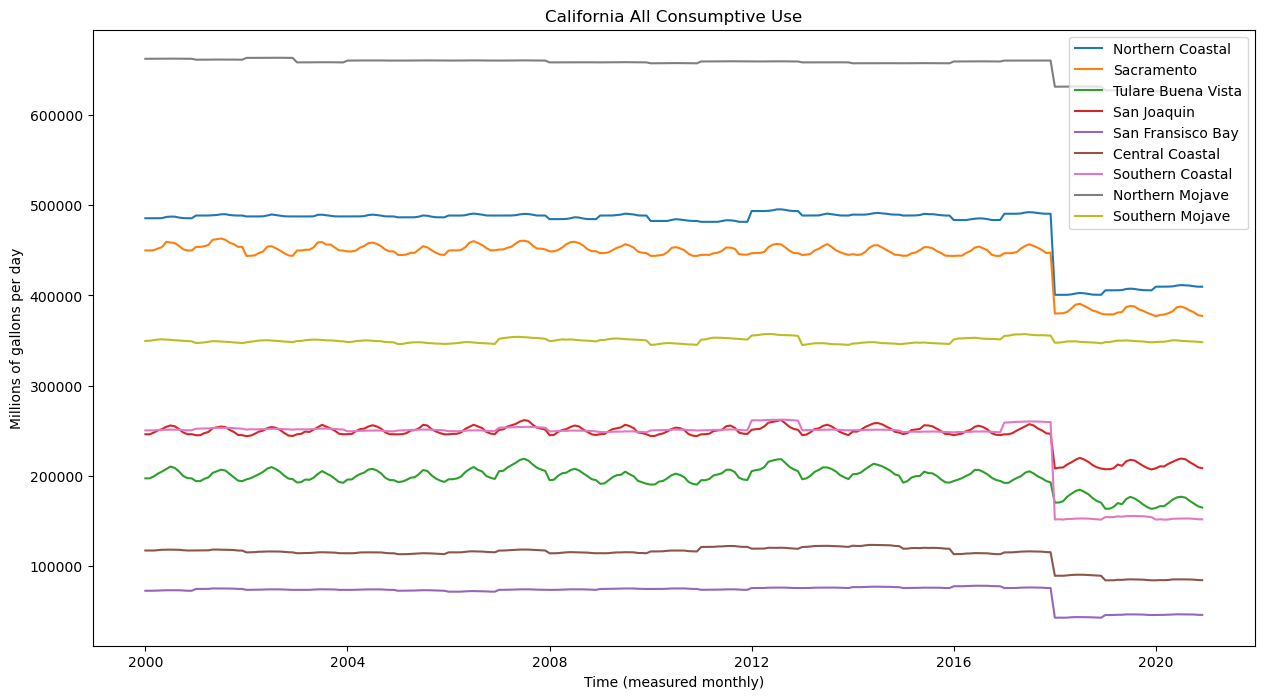

In [26]:
# adding all consumptive water use data together

huc_combined = {
    1801: [], 1802: [], 1803: [], 1804: [], 1805: [], 1806: [], 1807: [], 1809: [], 1810: []
    }

for key in huc_combined:
    huc_combined[key] = huc_Irr[key] + huc_PS[key]

plot_water(huc_combined, 'All')

In [27]:
# dictionary of rain
huc_rain = {
    1801: {
        "name": "Northern California",
        "subregions": ["Cloverdale-Northern California Coastal", "Eureka-Northern California Coastal", "Fort Bragg-Northern California Coastal"],
        "daily_rain":[],
        "rain":[]
    },
    1802: {
        "name": "Sacramento",
        "subregions": ["Jess Valley - Sacramento", "McCloud - Sacramento", "Quincy, Sacramento"],
        "daily_rain":[],
        "rain":[]
    },
    1803: {
        "name": "Tulare-Buena Vista",
        "subregions": ["Coalinga", "Fresno", "Visalia"],
        "daily_rain":[],
        "rain":[]
    },
    1804: {
        "name": "San Joaquin",
        "subregions": ["Mercer", 'Sanora', "West_Point"],
        "daily_rain":[],
        "rain":[]
    },
    1805: {
        "name": "San Fransico",
        "subregions": ["Fremont - San Fransisco", "Mount Hamilton - San Francisco Bay", "Richmond - San Fransisco"],
        "daily_rain":[],
        "rain":[]
    },
    1806: {
        "name": "Central Coastal",
        "subregions": ["Big_Sur", "Santa_Maria", "Watsonville"],
        "daily_rain":[],
        "rain":[]
    },
    1807: {
        "name": "Southern Cali Coastal",
        "subregions": ["Long Beach", "Oceanside", "San_Diego"],
        "daily_rain":[],
        "rain":[]
    },
    1809: {
        "name": "Northen Mojave",
        "subregions": ["Barstow", "Death_Valley", "Victorville"],
        "daily_rain":[],
        "rain":[]
    },
    1810: {
        "name": "Southern Mojave",
        "subregions": ["Iron_Mountain", "Niland", "Randsburg"],
        "daily_rain":[],
        "rain":[]
    }
}

In [28]:
# data_import = []
# region_names = []

# for huc in huc_rain:
#     for region in huc_rain[huc]["subregions"]:
#         region_name = region
#         data_import.append(f"'Data/Rainfall Data/{huc_rain[huc]['name']}/{region}.csv'")
#         print(f"{region_name.lower()} = 'Data/Rainfall Data/{huc_rain[huc]['name']}/{region}.csv'\n")

/var/folders/cv/v2937rks3wd_x0qtcsv5nc400000gn/T/ipykernel_48491/2485845173.py:17: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  start_index = int(np.where(time == start_day)[0])
/var/folders/cv/v2937rks3wd_x0qtcsv5nc400000gn/T/ipykernel_48491/2485845173.py:18: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  end_index = int(np.where(time == end_day)[0])


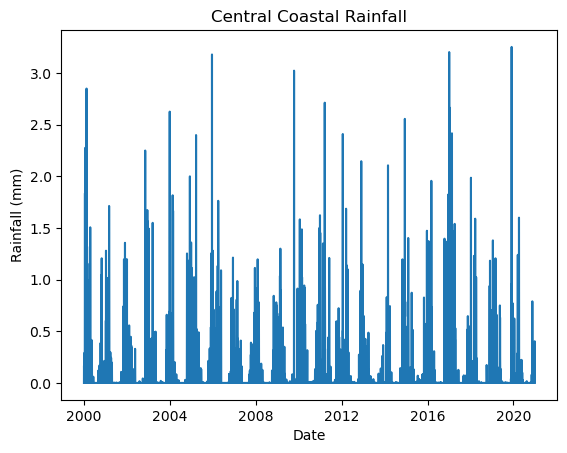

In [29]:
big_sur = 'Big_Sur.csv'
santa_maria = 'Santa_Maria.csv'
watsonville = 'Watsonville.csv'

def getrain(file):
    vars = ['date', 'b1', 'b2', 'b3', 'rain', 'b4', 'b5']
    tconvert = lambda x: datetime.strptime(x, '%Y-%m-%d')
    data = np.genfromtxt(file, skip_header=2, encoding='utf-8', dtype=None,
                         delimiter=',', converters={0: tconvert}, names=vars)

    time = data['date']
    rain = data['rain']
    rain = np.nan_to_num(rain, nan=0)

    start_day = datetime(2000, 1, 1)
    end_day = datetime(2021, 1, 1)
    start_index = int(np.where(time == start_day)[0])
    end_index = int(np.where(time == end_day)[0])

    return time[start_index:end_index], rain[start_index:end_index]
# Load and average rain from three stations
x1, y1 = getrain(watsonville)
x2, y2 = getrain(big_sur)
x3, y3 = getrain(santa_maria)


# Handles NaN values
rain = np.nanmean(np.vstack([y1, y2, y3]), axis=0)



# Plot
plt.plot(x1, rain)
plt.title('Central Coastal Rainfall')
plt.xlabel('Date')
plt.ylabel('Rainfall (mm)')
plt.show()


In [30]:
data_import = []
region_names = []

for huc in huc_rain:
    i = 0 # this will be used to check if it is the first region
    rain = []
    days = []
    for region in huc_rain[huc]["subregions"]: # for each region
        #CHANGE FILEPATH
            #just change the first part tho
        f = f"{region}.csv"
        # print(f)
        t, r = getrain(f) # get rain
        if (i == 0): # if it is the first subregion in the huc
            rain = r
        else: # if it is not the first subregion in the huc
            rain = rain + r # add it to the other rain data from this huc
        i+=1
        days = t

    rain = rain/3 # divide by 3 to get the average in the huc
    huc_rain[huc]["daily_rain"] = rain 

    # convert from daily to monthly rainfall
    rain_monthly = []
    month_rain = 0
    for i, day in enumerate(rain):
        if (days[i].day == 1):
            rain_monthly.append(month_rain)
            month_rain = day
        else:
            month_rain += day

    huc_rain[huc]["rain"] = rain_monthly  # <— this is what was missing
   

/var/folders/cv/v2937rks3wd_x0qtcsv5nc400000gn/T/ipykernel_48491/2485845173.py:17: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  start_index = int(np.where(time == start_day)[0])
/var/folders/cv/v2937rks3wd_x0qtcsv5nc400000gn/T/ipykernel_48491/2485845173.py:18: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  end_index = int(np.where(time == end_day)[0])


time length: 252
rain length: 252
water use length: 252


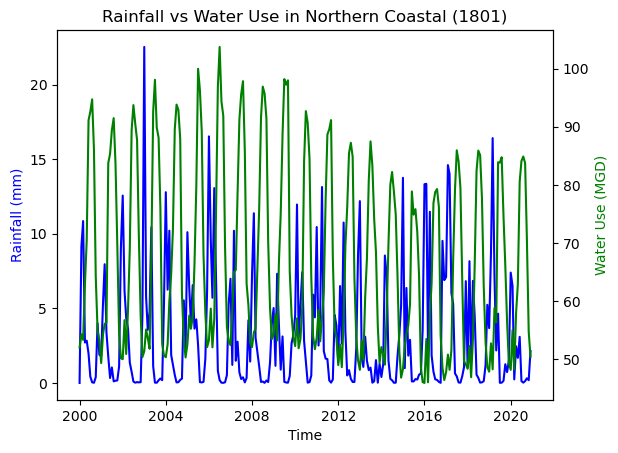

In [31]:
print("time length:", len(time))  # Should be 252
print("rain length:", len(huc_rain[1801]["rain"]))  # Should also be 252
print("water use length:", len(huc_PS[1801]))  # Should also be 252

fig, ax1 = plt.subplots()

ax1.plot(time, huc_rain[1801]["rain"], color='blue')
ax1.set_xlabel('Time')
ax1.set_ylabel('Rainfall (mm)', color='blue')

ax2 = ax1.twinx()
ax2.plot(time, huc_PS[1801], color='green')
ax2.set_ylabel('Water Use (MGD)', color='green')

plt.title('Rainfall vs Water Use in Northern Coastal (1801)')
plt.show()

In [32]:
print(np.corrcoef(huc_PS[1804], huc_rain[1804]["rain"]))

print(np.corrcoef(huc_combined[1804], huc_rain[1804]["rain"]))

[[ 1.         -0.51773969]
 [-0.51773969  1.        ]]
[[ 1.         -0.11852971]
 [-0.11852971  1.        ]]


In [33]:
index_2000 = int(np.where(time == datetime(2000, 1, 1))[0])
index_2018 = int(np.where(time == datetime(2018, 1, 1))[0])
index_2020 = int(np.where(time == datetime(2020, 12, 1))[0])

print(np.mean(huc_combined[1810][index_2000:index_2018]))
print(np.mean(huc_combined[1810][index_2018:index_2020]))

349878.7169016227
348759.7614723242


/var/folders/cv/v2937rks3wd_x0qtcsv5nc400000gn/T/ipykernel_48491/1737525840.py:1: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  index_2000 = int(np.where(time == datetime(2000, 1, 1))[0])
/var/folders/cv/v2937rks3wd_x0qtcsv5nc400000gn/T/ipykernel_48491/1737525840.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  index_2018 = int(np.where(time == datetime(2018, 1, 1))[0])
/var/folders/cv/v2937rks3wd_x0qtcsv5nc400000gn/T/ipykernel_48491/1737525840.py:3: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this ope

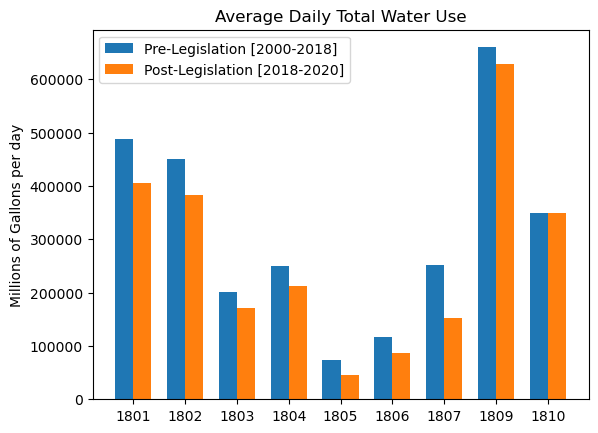

In [34]:
hucs = []
pre_leg = []
post_leg = []

for huc in huc_combined:
    hucs.append(huc)
    pre_leg.append(np.mean(huc_combined[huc][index_2000:index_2018]))
    post_leg.append(np.mean(huc_combined[huc][index_2018:index_2020]))

x = np.arange(len(hucs))
width = 0.35  # Width of each bar

# Create the plot
fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, pre_leg, width, label='Pre-Legislation [2000-2018]')
rects2 = ax.bar(x + width/2, post_leg, width, label='Post-Legislation [2018-2020]')

# Add labels, title, and legend
ax.set_ylabel('Millions of Gallons per day')
ax.set_title('Average Daily Total Water Use')
ax.set_xticks(x)
ax.set_xticklabels(hucs)
ax.legend()

# Display the chart
plt.show()


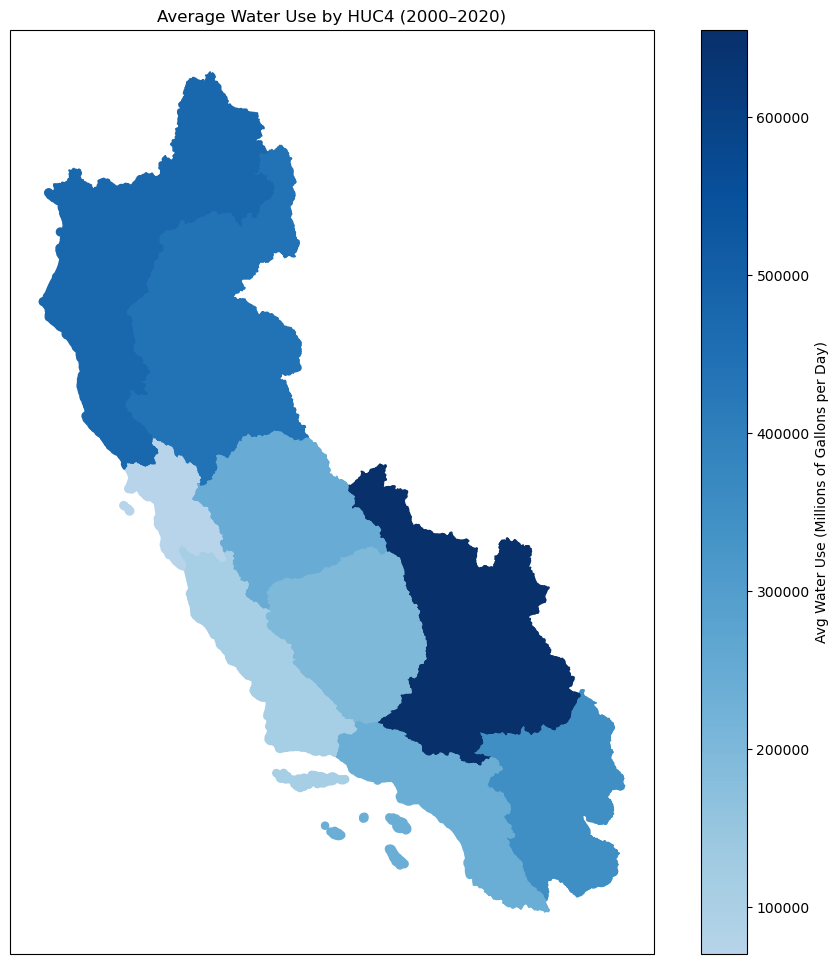

In [35]:

# Load JSON
with open('b7974dff79ff41f0bd3cd4d8f248c6f4.json') as file:
    geo = json.load(file)

# Build average water use dictionary
huc_avg = {str(k): sum(v)/len(v) for k, v in huc_combined.items()}

# Uses Mercator projection because coordinates are in Web Mercator (meters)
fig, ax = plt.subplots(figsize=(12, 12), subplot_kw={'projection': ccrs.Mercator.GOOGLE})
ax.set_title('Average Water Use by HUC4 (2000–2020)')

# Color scale for the map
vals = list(huc_avg.values())
norm = Normalize(vmin=min(vals), vmax=max(vals))
cmap =  matplotlib.colors.LinearSegmentedColormap.from_list(
    "darker_blues", plt.cm.Blues(np.linspace(0.3, 1.0, 256))
)

# Get and filter features per region
features = geo['layers'][0]['features']
for feature in features:
    props = feature['attributes']
    huc4 = str(props.get('huc4')) 

    if huc4 not in d:
        continue  

    # If not in HUC 4 colors grey to be neutral
    color = cmap(norm(huc_avg[huc4])) if huc4 in huc_avg else 'lightgrey'

    # 
    for ring in feature['geometry']['rings']:
        xs, ys = zip(*ring)
        ax.fill(xs, ys, color=color, transform=ccrs.Mercator.GOOGLE)

# Adds legend to graph
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
plt.colorbar(sm, ax=ax, label='Avg Water Use (Millions of Gallons per Day)')
plt.show()

This map represents the Average Water Use by HUC4 focusing on the time period between 2000-2020. We see that the lighter shades of blue represent a lower average water use and the darker shades of blue represent a higher average water use. Looking at Northern California, we can see that the average water use is on the higher end when looking at the legend, we see that the average water use is around 400,000 to 500,000, and because it's a darker blue we can infer that it's closer to 500,000, probably 490,000. The lighter shades of blue represent the region of Central Coastal, where we can see using the legend that the light blue means that the average water use is around 100,000 million gallons per day. Lastly, the darkest shade of blue similar to navy represents the region of northern Mojave. Using the legend, we see that the average water use is at its peak, above 600,000 million gallons per day.

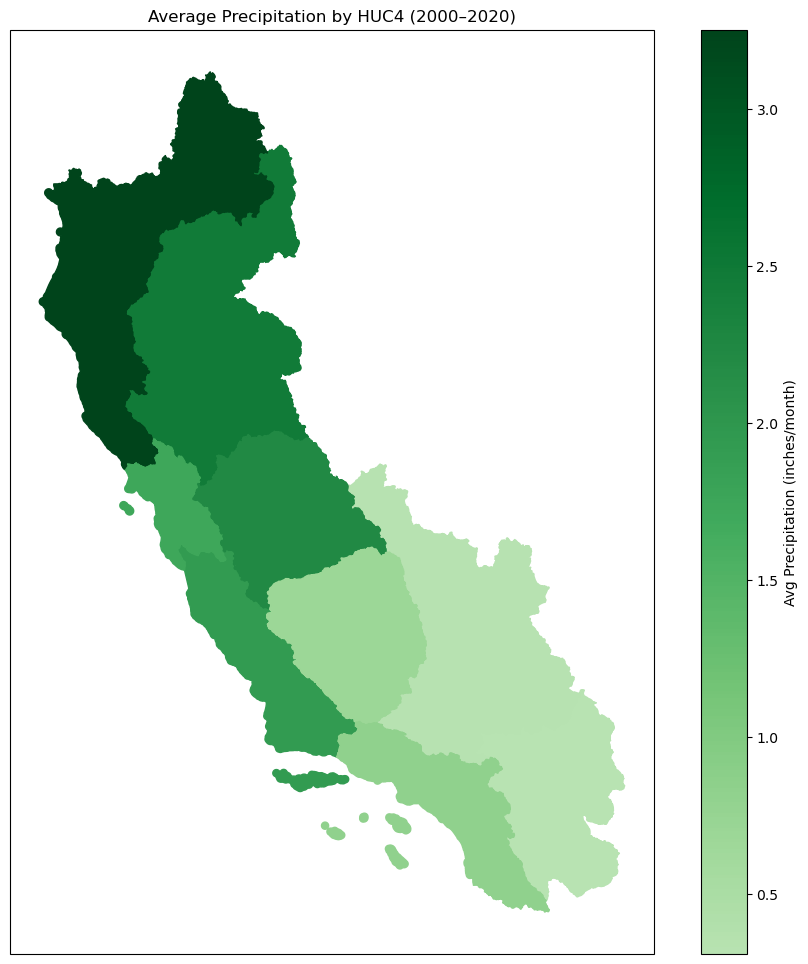

In [36]:

## INCLUDE THESE:

## import cartopy.crs as ccrs
## web_mercator = ccrs.Mercator.GOOGLE
## import cartopy.feature as cfeature
## rom cartopy.crs import PlateCarree

# Build average water use dictionary
huc_avg = {
    str(huc): sum(huc_rain[huc]['rain']) / len(huc_rain[huc]['rain']) 
    for huc in huc_rain 
    if len(huc_rain[huc]['rain']) > 0
}

# Use Mercator projection because coordinates are in Web Mercator (meters)
fig, ax = plt.subplots(figsize=(12, 12), subplot_kw={'projection': ccrs.Mercator.GOOGLE})
ax.set_title('Average Precipitation by HUC4 (2000–2020)')

# Color scale
vals = list(huc_avg.values())
norm = Normalize(vmin=min(vals), vmax=max(vals))
cmap =  matplotlib.colors.LinearSegmentedColormap.from_list(
    "darker_greens", plt.cm.Greens(np.linspace(0.3, 1.0, 256))
)

# Get and filter features
features = geo['layers'][0]['features']
for feature in features:
    props = feature['attributes']
    huc4 = str(props.get('huc4'))  # use correct lowercase key

    if huc4 not in d:
        continue  # skip non-CA regions

    color = cmap(norm(huc_avg[huc4])) if huc4 in huc_avg else 'lightgrey'

    for ring in feature['geometry']['rings']:
        xs, ys = zip(*ring)
        ax.fill(xs, ys, color=color, transform=ccrs.Mercator.GOOGLE)

# Add legend
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
plt.colorbar(sm, ax=ax, label='Avg Precipitation (inches/month)')
plt.show()

This map represents the Average Precipitation by HUC4 across California focusing on the region between 2000 and 2020. Looking at the north, where the shade of green is the darkest, we can see that the average precipitation is at its peak, where we can infer that the average precipitation is around 3 inches. Looking down below where there is a medium shade of green, this region represents central coastal. Using the legend, we can see that the average precipitation is around 2 inches. Lastly, the region that has the lightest shade of green represents Northern Mojave. Here we can see that the average precipitation falls closer to 0.5 inches. One interesting thing is that when comparing the average precipitation graph with the average water use graph, we can see that northern Mojave has the lowest average precipitation while having the highest average water use. This is something important to keep note of, and we will look for possible factors for this observation.